<a href="https://colab.research.google.com/github/daviminati/Trab_Final_IA/blob/main/Sprint__3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sprint 3: Mecanismos de Atenção (Coding Attention Mechanisms)

**Disciplina / Projeto Integrador LLM**

Este notebook contempla a implementação completa do **Capítulo 3** do livro *Build a Large Language Model (From Scratch)* de Sebastian Raschka. Aqui construímos passo a passo os mecanismos de atenção que formam o coração da arquitetura Transformer/GPT.

**Pipeline implementado:** Entradas de Exemplo $\rightarrow$ Atenção Simples sem Pesos $\rightarrow$ Self-Attention com Pesos ($W_q, W_k, W_v$) $\rightarrow$ Causal Attention (Máscara Autoregressiva) $\rightarrow$ Multi-Head Attention

In [8]:
# 1. Configuração de ambiente e importações fundamentais
from importlib.metadata import version
import torch
import torch.nn as nn

print("torch version:", version("torch"))

torch version: 2.11.0+cpu


## 3.1 e 3.2 Introdução aos Mecanismos de Atenção e Cálculo Sem Pesos

Nesta etapa, entendemos por que modelos de linguagem utilizam atenção para capturar dependências em sequências de texto (superando gargalos de RNNs) e construímos uma primeira versão simplificada do mecanismo para entender a matemática por trás do vetor de contexto.

Nesta seção, implementamos:
1. Uma **matriz de entrada fictícia** de 6 tokens com embeddings de dimensão 3.
2. O cálculo manual do **vetor de contexto** para um token específico usando produto escalar e normalização Softmax.
3. A extensão para toda a matriz via produto matricial ($X \cdot X^T$).

In [9]:
# Mapeamento e cálculo da atenção sem pesos treináveis

# Exemplo de entrada: 6 tokens, embedding de dimensão 3
inputs = torch.tensor(
  [[0.43, 0.15, 0.89], # Your     (x^1)
   [0.55, 0.87, 0.66], # journey  (x^2)
   [0.57, 0.85, 0.22], # calculated (x^3)
   [0.22, 0.58, 0.33], # steps    (x^4)
   [0.77, 0.25, 0.10], # forward  (x^5)
   [0.05, 0.80, 0.55]] # .        (x^6)
)

# 1. Cálculo de atenção manual para o token 2 ("journey")
query = inputs[1]
attn_scores_2 = torch.empty(inputs.shape[0])

for i, x_i in enumerate(inputs):
    attn_scores_2[i] = torch.dot(x_i, query)

# Normalização com Softmax
attn_weights_2 = torch.softmax(attn_scores_2, dim=0)

# Vetor de contexto do token 2
context_vec_2 = torch.zeros(query.shape)
for i, x_i in enumerate(inputs):
    context_vec_2 += attn_weights_2[i] * x_i

print("Vetor de contexto do token 2 (sem pesos):", context_vec_2)

# 2. Generalização para a matriz completa de pontuações de atenção
attn_scores = inputs @ inputs.T
attn_weights = torch.softmax(attn_scores, dim=-1)
all_context_vecs = attn_weights @ inputs

print("\nMatriz completa de pesos de atenção:\n", attn_weights)

Vetor de contexto do token 2 (sem pesos): tensor([0.4342, 0.6396, 0.4853])

Matriz completa de pesos de atenção:
 tensor([[0.2237, 0.2138, 0.1453, 0.1324, 0.1301, 0.1547],
        [0.1468, 0.2521, 0.1874, 0.1314, 0.1147, 0.1676],
        [0.1233, 0.2314, 0.2089, 0.1394, 0.1369, 0.1601],
        [0.1474, 0.2130, 0.1829, 0.1502, 0.1297, 0.1767],
        [0.1539, 0.1974, 0.1909, 0.1378, 0.1894, 0.1306],
        [0.1448, 0.2284, 0.1766, 0.1486, 0.1033, 0.1983]])


## 3.3 Self-Attention com Pesos Treináveis ($W_q, W_k, W_v$)

Avançamos da atenção simples para a **Self-Attention** propriamente dita, onde o modelo aprende três matrizes de projeção separadas:
* **Query ($Q$):** Representa o que o token atual está "procurando".
* **Key ($K$):** Representa o que o token "oferece" como informação.
* **Value ($V$):** Representa o conteúdo que será repassado ao vetor de contexto.

Implementamos o mecanismo em duas versões: `SelfAttention_v1` (usando `nn.Parameter`) e `SelfAttention_v2` (usando `nn.Linear` do PyTorch).

In [10]:
# Implementação do mecanismo de Self-Attention com pesos treináveis

class SelfAttention_v1(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.W_query = nn.Parameter(torch.rand(d_in, d_out))
        self.W_key   = nn.Parameter(torch.rand(d_in, d_out))
        self.W_value = nn.Parameter(torch.rand(d_in, d_out))

    def forward(self, x):
        queries = x @ self.W_query
        keys    = x @ self.W_key
        values  = x @ self.W_value

        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)

        context_vec = attn_weights @ values
        return context_vec

class SelfAttention_v2(nn.Module):
    def __init__(self, d_in, d_out, qkv_bias=False):
        super().__init__()
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

    def forward(self, x):
        queries = self.W_query(x)
        keys    = self.W_key(x)
        values  = self.W_value(x)

        attn_scores = queries @ keys.T
        attn_weights = torch.softmax(attn_scores / keys.shape[-1]**0.5, dim=-1)

        context_vec = attn_weights @ values
        return context_vec

# Testando a classe SelfAttention_v2
d_in, d_out = inputs.shape[1], 2
torch.manual_seed(789)
sa_v2 = SelfAttention_v2(d_in, d_out)
print("Saída do SelfAttention_v2:\n", sa_v2(inputs))

Saída do SelfAttention_v2:
 tensor([[-0.0608,  0.0843],
        [-0.0620,  0.0826],
        [-0.0632,  0.0810],
        [-0.0628,  0.0816],
        [-0.0630,  0.0813],
        [-0.0624,  0.0821]], grad_fn=<MmBackward0>)


## 3.4 Mascaramento Autoregressivo (Causal Attention)

Para treinar um modelo de linguagem estilo GPT (decoder-only), o modelo não pode "olhar para o futuro" durante o cálculo da atenção.

Nesta seção, implementamos:
1. Uma **máscara causal triangular** substituindo os valores futuros por $-\infty$ nas pontuações de atenção antes do Softmax.
2. Suporte a **Dropout** para regularização do modelo.
3. A classe `CausalAttention` preparada para receber lotes de dados (batches).

In [11]:
# Implementação da Atenção Causal (Decoder Masking)

class CausalAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)

        # Buffer com a máscara triangular superior
        self.register_buffer(
            'mask',
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        queries = self.W_query(x)
        keys    = self.W_key(x)
        values  = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2)
        attn_scores.masked_fill_(
            self.mask[:num_tokens, :num_tokens].bool(),
            -torch.inf
        )
        attn_weights = torch.softmax(attn_scores / (keys.shape[-1]**0.5), dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = attn_weights @ values
        return context_vec

# Teste com batch de tamanho 2
batch = torch.stack((inputs, inputs), dim=0)
torch.manual_seed(123)
context_length = batch.shape[1]
ca = CausalAttention(d_in, d_out, context_length, dropout=0.0)

print("Dimensão do lote de entrada:", batch.shape)
print("Dimensão da saída do CausalAttention:", ca(batch).shape)

Dimensão do lote de entrada: torch.Size([2, 6, 3])
Dimensão da saída do CausalAttention: torch.Size([2, 6, 2])


## 3.5 Multi-Head Attention (Atenção Multicabeça Eficiente)

Por fim, expandimos a atenção para **múltiplas cabeças (heads)**. Isso permite que o modelo aprenda diferentes tipos de relações entre os tokens simultaneamente.

Implementamos a classe final `MultiHeadAttention`, que divide as projeções lineares das dimensões de $Q, K, V$ em múltiplos subsistemas paralelos de forma computacionalmente eficiente usando `.view()` e `.transpose()`.

In [12]:
# Implementação eficiente da Multi-Head Attention

class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out precisa ser divisível por num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key   = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            'mask',
            torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys    = self.W_key(x)
        queries = self.W_query(x)
        values  = self.W_value(x)

        # Divisão das dimensões em múltiplas cabeças
        keys    = keys.view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)
        values  = values.view(b, num_tokens, self.num_heads, self.head_dim).transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)
        mask_bool = self.mask[:num_tokens, :num_tokens].bool()

        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / (keys.shape[-1]**0.5), dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        return self.out_proj(context_vec)

# Validação do modelo Multi-Head final
torch.manual_seed(123)
mha = MultiHeadAttention(d_in=3, d_out=2, context_length=6, dropout=0.0, num_heads=2)
output = mha(batch)

print("Saída do MultiHeadAttention final:\n", output)
print("Shape final:", output.shape)

Saída do MultiHeadAttention final:
 tensor([[[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2671, 0.3679],
         [0.2563, 0.3936],
         [0.2536, 0.3982],
         [0.2487, 0.4071]],

        [[0.3190, 0.4858],
         [0.2943, 0.3897],
         [0.2671, 0.3679],
         [0.2563, 0.3936],
         [0.2536, 0.3982],
         [0.2487, 0.4071]]], grad_fn=<ViewBackward0>)
Shape final: torch.Size([2, 6, 2])


## 3.6 Experimentos e Análise dos Mecanismos de Atenção

Para validar o funcionamento dos módulos implementados, realizamos dois experimentos práticos:
1. **Inspeção Visual da Matriz Causal:** Plotagem do mapa de calor dos pesos de atenção para confirmar que os tokens futuros foram mascarados (valores zerados na parte superior).
2. **Impacto da Múltipla Cabeça (Multi-Head vs Single-Head):** Comparação das dimensões internas de projeção ao aumentar o número de cabeças de atenção ($N_{heads}$).

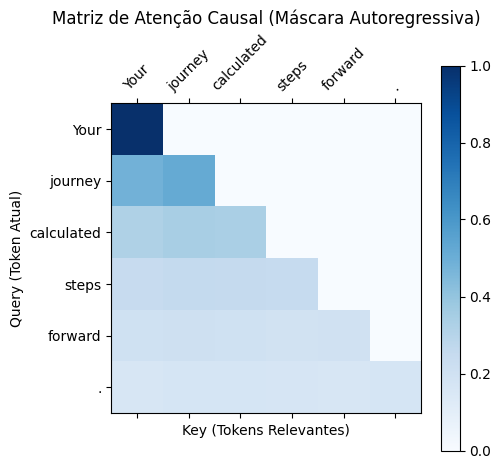

In [13]:
import matplotlib.pyplot as plt

# 1. Extraindo a matriz de pesos de atenção do CausalAttention (sem dropout para visualizar)
torch.manual_seed(123)
causal_test = CausalAttention(d_in=3, d_out=2, context_length=6, dropout=0.0)

# Passando o batch para capturar a matriz interna de atenção
queries = causal_test.W_query(batch[0])
keys = causal_test.W_key(batch[0])
attn_scores = queries @ keys.T
attn_scores.masked_fill_(causal_test.mask.bool(), -torch.inf)
attn_weights = torch.softmax(attn_scores / (keys.shape[-1]**0.5), dim=-1)

# Plot do Heatmap
fig, ax = plt.subplots(figsize=(5, 5))
cax = ax.matshow(attn_weights.detach().numpy(), cmap='Blues')
fig.colorbar(cax)

tokens = ["Your", "journey", "calculated", "steps", "forward", "."]
ax.set_xticks(range(len(tokens)))
ax.set_yticks(range(len(tokens)))
ax.set_xticklabels(tokens, rotation=45)
ax.set_yticklabels(tokens)

plt.xlabel("Key (Tokens Relevantes)")
plt.ylabel("Query (Token Atual)")
plt.title("Matriz de Atenção Causal (Máscara Autoregressiva)")
plt.show()

In [14]:
# Experimento variando a dimensão e o número de cabeças

d_in = 768  # Configuração padrão do GPT-2
d_out = 768

print("--- Teste de Configurações do Multi-Head Attention ---")

for num_heads in [1, 4, 8, 12]:
    mha_exp = MultiHeadAttention(
        d_in=d_in,
        d_out=d_out,
        context_length=1024,
        dropout=0.1,
        num_heads=num_heads
    )
    print(f"Num Heads: {num_heads:2d} | Dimensão por Cabeça (head_dim): {mha_exp.head_dim:3d}")

--- Teste de Configurações do Multi-Head Attention ---
Num Heads:  1 | Dimensão por Cabeça (head_dim): 768
Num Heads:  4 | Dimensão por Cabeça (head_dim): 192
Num Heads:  8 | Dimensão por Cabeça (head_dim):  96
Num Heads: 12 | Dimensão por Cabeça (head_dim):  64


## Conclusões da Sprint 3 e Organização do Trabalho

### 📊 Análise dos Experimentos
1. **Máscara Causal:** O mapa de calor gerado confirma o comportamento autoregressivo. Todos os pesos de atenção acima da diagonal principal são iguais a zero, garantindo que o modelo aprenda a prever a próxima palavra sem olhar para os tokens futuros.
2. **Multi-Head Attention:** A variação no número de cabeças ($N_{heads}$) demonstra como a dimensão interna é dividida ($head\_dim = d_{out} / N_{heads}$). Na configuração padrão do GPT-2 ($768$ dimensões e $12$ cabeças), cada cabeça opera em um subespaço de $64$ dimensões, mantendo o custo computacional controlado enquanto permite ao modelo focar em diferentes tipos de relações de texto simultaneamente.

---

### 🤝 Divisão de Trabalho da Dupla

* **Integrante 1:** Leitura, implementação e documentação das seções **3.1, 3.2 e 3.3** (Atenção simples, matrizes $W_q, W_k, W_v$ e classes `SelfAttention_v1` / `SelfAttention_v2`).
* **Integrante 2:** Leitura, implementação e documentação das seções **3.4, 3.5 e 3.6** (Máscara autoregressiva com `CausalAttention`, módulo `MultiHeadAttention` e experimentos visuais).

In [15]:
# Teste final de integração do módulo para a próxima Sprint
print("--- Validação do Módulo de Atenção para a Sprint 4 ---")

mha_final = MultiHeadAttention(
    d_in=768,
    d_out=768,
    context_length=1024,
    dropout=0.1,
    num_heads=12
)

# Simulando um batch de dados reais de entrada
exemplo_batch = torch.randn(2, 6, 768)
saida_final = mha_final(exemplo_batch)

print(f"Entrada no formato GPT-2: {exemplo_batch.shape}")
print(f"Saída processada com sucesso: {saida_final.shape}")
print("\n✅ Módulo de Atenção da Sprint 3 totalmente validado!")

--- Validação do Módulo de Atenção para a Sprint 4 ---
Entrada no formato GPT-2: torch.Size([2, 6, 768])
Saída processada com sucesso: torch.Size([2, 6, 768])

✅ Módulo de Atenção da Sprint 3 totalmente validado!
